# 1 · Data and imbalance

**Question of the study:** does generating extra images for the rare classes of an imbalanced dataset make a classifier better?

This notebook looks at the data. It reads the saved split file (`experiment/splits/split.csv`); nothing is trained here. The whole study
is described in the [README](../README.md), the evaluation rules in [`experiment/PROTOCOL.md`](../experiment/PROTOCOL.md).

Dataset: the original **PlantVillage** colour photos, *before* any augmentation (a few leaves do appear in more than one photo). (The first version of this project used a
Kaggle copy that had been artificially balanced with rotated and flipped copies, which hid the imbalance and leaked copies between splits.)

In [1]:
%matplotlib inline
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import study
from study import metrics, LEVELS, METHODS, LABEL, COLOR
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.axisbelow": True})
pd.set_option("display.width", 140)

In [2]:
counts = study.split_counts()
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total", ascending=False)
minority = metrics.MINORITY_CLASSES
print(f"{len(counts)} classes, {counts['total'].sum():,} images")
print(f"largest class {counts['total'].max():,}, smallest {counts['total'].min()}: imbalance ratio {counts['total'].max()/counts['total'].min():.1f} : 1")
print(f"classes with fewer than {metrics.MINORITY_THRESHOLD} images: {(counts['total'] < metrics.MINORITY_THRESHOLD).sum()}  (the 'minority' classes)")
print(f"the 3 largest classes hold {counts['total'].head(3).sum()/counts['total'].sum():.0%} of all images")
print("split sizes:", counts[['train','val','test']].sum().to_dict())

38 classes, 54,305 images
largest class 5,507, smallest 152: imbalance ratio 36.2 : 1
classes with fewer than 500 images: 7  (the 'minority' classes)
the 3 largest classes hold 29% of all images
split sizes: {'train': 43444, 'val': 5430, 'test': 5431}


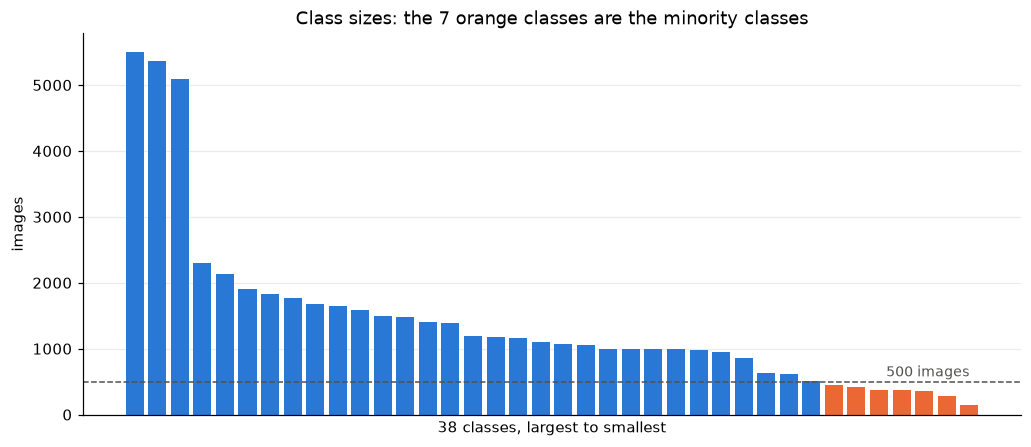

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = ["#eb6834" if c in minority else "#2a78d6" for c in counts.index]
ax.bar(range(len(counts)), counts["total"], color=colors)
ax.axhline(metrics.MINORITY_THRESHOLD, color="#52514e", lw=1, ls="--")
ax.text(len(counts) - 1, metrics.MINORITY_THRESHOLD + 80, f"{metrics.MINORITY_THRESHOLD} images", ha="right", color="#52514e", fontsize=9)
ax.set_xticks([]); ax.set_xlabel("38 classes, largest to smallest"); ax.set_ylabel("images")
ax.set_title("Class sizes: the 7 orange classes are the minority classes")
plt.show()

## The 7 minority classes

These are fixed in `metrics.py` before any model is trained. Every method is judged mainly on how well it does on *these* classes.

In [4]:
counts.loc[minority, ["train", "val", "test", "total"]]

split,train,val,test,total
class,,,,
Potato___healthy,122,15,15,152
Apple___Cedar_apple_rust,220,28,27,275
Peach___healthy,288,36,36,360
Raspberry___healthy,297,37,37,371
Tomato___Tomato_mosaic_virus,298,38,37,373
Grape___healthy,338,43,42,423
Strawberry___healthy,365,46,45,456


## Why accuracy is the wrong measure here

The minority classes are a tiny share of the test set. A model that gets **every one of them wrong** still scores very high accuracy.

In [5]:
test = counts["test"]
share = test[minority].sum() / test.sum()
print(f"minority classes are {share:.1%} of the test images")
print(f"a classifier that misclassifies ALL of them still gets {1 - share:.1%} accuracy, but 0.0 minority macro-F1")

minority classes are 4.4% of the test images
a classifier that misclassifies ALL of them still gets 95.6% accuracy, but 0.0 minority macro-F1


So the study uses **minority macro-F1** (mean F1 over the 7 classes) as its primary measure and macro-F1 over all 38 classes as the co-primary one;
accuracy is reported only for context.

## Imbalance levels

To see how methods behave as the problem gets harder, the minority classes are also shrunk to **100** or **30** real training images each
(nested subsets, fixed seed). Validation and test sets are never touched.